<a href="https://colab.research.google.com/github/Kutay33/GROUP60_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 – EDA & Baselines
**Competition:** [Hull Tactical – Market Prediction](https://www.kaggle.com/competitions/hull-tactical-market-prediction)

Goal: each day, choose how much of the S&P 500 to hold (**position between 0 and 2**) so that the
volatility‑adjusted Sharpe ratio is as high as possible.

Contents
1. Setup (Colab)
2. Data overview
3. Missing values
4. Target analysis
5. Feature–target relationships
6. Baselines

## 1. Setup
Run this on Colab. Upload your `kaggle.json` (Kaggle → Settings → *Create New Token*) when asked.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/Kutay33/GROUP60_CENG313.git'
ROOT = '/content/GROUP60_CENG313'

if IN_COLAB:
    os.chdir('/content')
    if not os.path.exists(ROOT):
        !git clone -q $REPO
    os.chdir(ROOT)
    if not os.path.exists('data/train.csv'):
        if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
            from google.colab import files
            files.upload()                      # select kaggle.json
            !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
        !kaggle competitions download -c hull-tactical-market-prediction -p data -q
        !unzip -oq data/hull-tactical-market-prediction.zip -d data
sys.path.append('.')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data as D
from src import utils as U

U.set_seed(42)
pd.set_option('display.max_columns', 50)

## 2. Data overview

In [3]:
train = D.load_train()
test = D.load_test()
feats = D.feature_columns(train)
print('train:', train.shape, ' test:', test.shape, ' features:', len(feats))
train.head()

train: (9048, 98)  test: (10, 99)  features: 94


,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,E1,E10,E11,E12,E13,E14,E15,E16,E17,E18,E19,E2,E20,E3,E4,...,S12,S2,S3,S4,S5,S6,S7,S8,S9,V1,V10,V11,V12,V13,V2,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,market_forward_excess_returns
0,0,0,0,0,1,1,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0,0,0,1,1,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0,0,0,1,0,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0,0,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0,0,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301


In [4]:
groups = pd.Series([D.group_of(c) for c in feats]).value_counts().sort_index()
groups.index = [f"{g} – {D.FEATURE_GROUPS[g]}" for g in groups.index]
groups.to_frame('n_features')

,n_features
D – Dummy / binary,9
E – Macro economic,20
I – Interest rate,9
M – Market dynamics / technical,18
P – Price / valuation,13
S – Sentiment,12
V – Volatility,13


In [5]:
print('Columns only in train:', sorted(set(train.columns) - set(test.columns)))
print('Columns only in test :', sorted(set(test.columns) - set(train.columns)))

Columns only in train: ['forward_returns', 'market_forward_excess_returns', 'risk_free_rate']
Columns only in test : ['is_scored', 'lagged_forward_returns', 'lagged_market_forward_excess_returns', 'lagged_risk_free_rate']


**Note:** `forward_returns`, `risk_free_rate` and `market_forward_excess_returns` describe the *next* day,
so they are targets / scoring inputs, not features. The test set only has their **lagged** versions.

## 3. Missing values

In [6]:
miss = D.missing_summary(train)
miss.head(20)

,feature,group,missing_ratio,first_valid_date_id
0,E7,E,0.770225,6969
1,V10,V,0.668546,6049
2,S3,S,0.633621,5733
3,M1,M,0.613064,5547
4,M13,M,0.612290,5540
5,M14,M,0.612290,5540
6,M6,M,0.557361,5043
7,V9,V,0.501658,4539
8,S12,S,0.390915,3537
9,M5,M,0.362843,3283


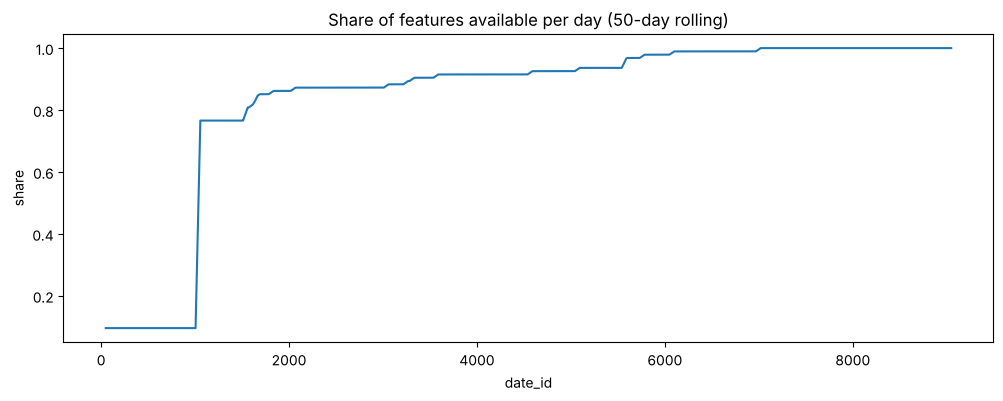

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
avail = train[feats].notna().mean(axis=1).rolling(50).mean()
ax.plot(train['date_id'], avail)
ax.set(title='Share of features available per day (50-day rolling)', xlabel='date_id', ylabel='share')
plt.show()

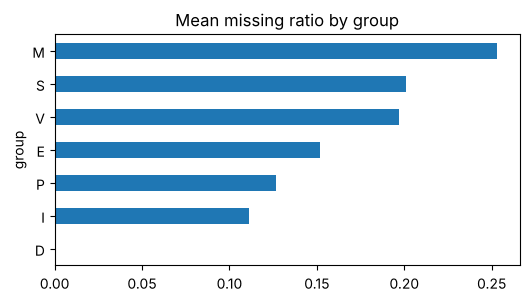

In [8]:
miss.groupby('group')['missing_ratio'].mean().sort_values().plot.barh(figsize=(6, 3), title='Mean missing ratio by group')
plt.show()

Older dates have many missing features; most features become available later. In the baselines we
drop the oldest, mostly empty rows and forward‑fill the rest.

## 4. Target analysis

In [9]:
y = train[D.TARGET]
y.describe()

count    9048.000000
mean        0.000052
std         0.010552
min        -0.040582
25%        -0.004751
50%         0.000257
75%         0.005469
max         0.040551
Name: market_forward_excess_returns, dtype: float64

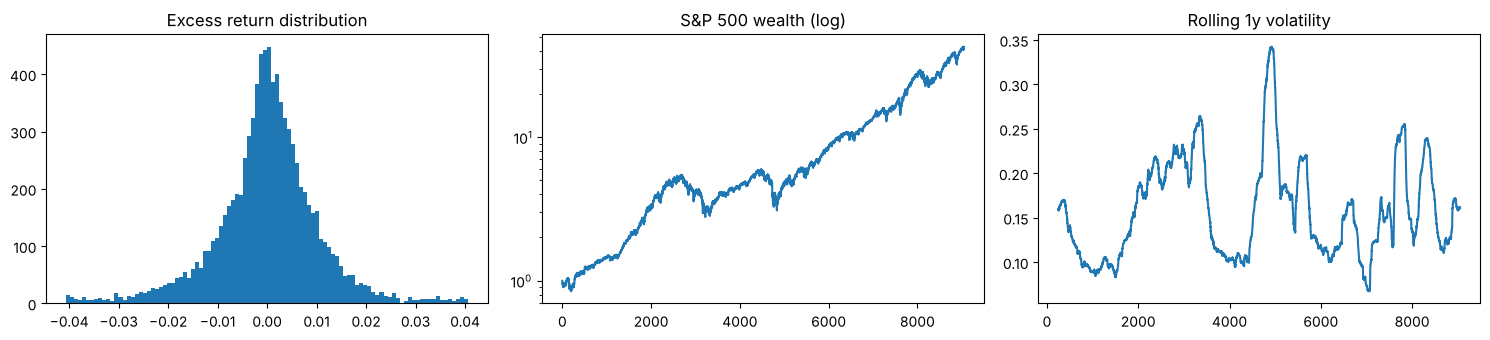

skew: -0.18  kurtosis: 2.244  share positive days: 0.517


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(y, bins=100); axes[0].set_title('Excess return distribution')
axes[1].plot(train['date_id'], (1 + train['forward_returns']).cumprod()); axes[1].set_yscale('log')
axes[1].set_title('S&P 500 wealth (log)')
axes[2].plot(train['date_id'], train['forward_returns'].rolling(252).std() * np.sqrt(252))
axes[2].set_title('Rolling 1y volatility')
plt.tight_layout(); plt.show()
print('skew:', y.skew().round(3), ' kurtosis:', y.kurt().round(3), ' share positive days:', (y > 0).mean().round(3))

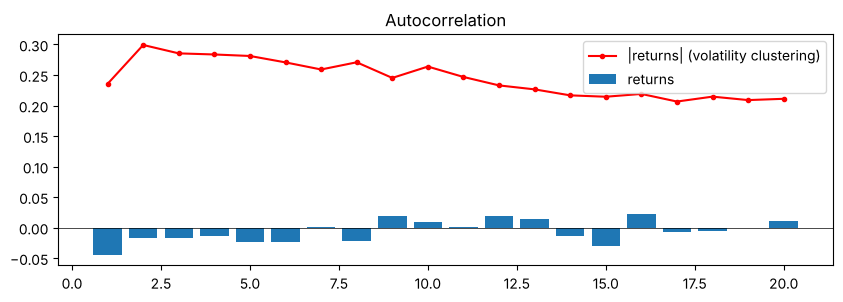

In [11]:
from pandas.plotting import autocorrelation_plot
fig, ax = plt.subplots(figsize=(10, 3))
lags = range(1, 21)
ax.bar(lags, [y.autocorr(l) for l in lags], label='returns')
ax.plot(lags, [y.abs().autocorr(l) for l in lags], 'r.-', label='|returns| (volatility clustering)')
ax.axhline(0, color='k', lw=.5); ax.legend(); ax.set_title('Autocorrelation')
plt.show()

Returns are close to unpredictable (tiny autocorrelation) but **absolute** returns are strongly
autocorrelated → volatility is predictable. This suggests a strategy that lowers exposure in high‑volatility periods.

## 5. Feature–target relationships

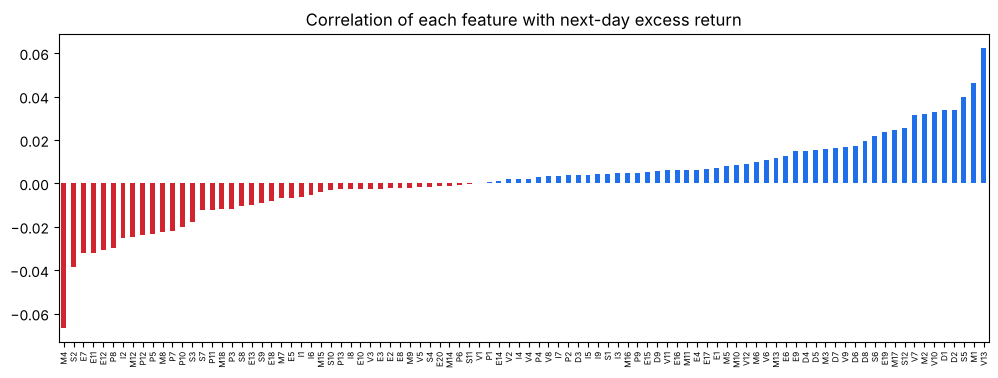

,corr
M4,-0.066632
S2,-0.038493
E7,-0.032230
E11,-0.032007
E12,-0.030813
P8,-0.029628
I2,-0.025281
M12,-0.024569
V7,0.031623
M2,0.032166


In [12]:
tr = D.drop_early_rows(train)
corr = tr[feats].corrwith(tr[D.TARGET]).dropna().sort_values()
fig, ax = plt.subplots(figsize=(12, 4))
corr.plot.bar(ax=ax, color=['#d1242f' if v < 0 else '#1f6feb' for v in corr])
ax.set_title('Correlation of each feature with next-day excess return'); ax.tick_params(axis='x', labelsize=6)
plt.show()
pd.concat([corr.head(8), corr.tail(8)]).to_frame('corr')

/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


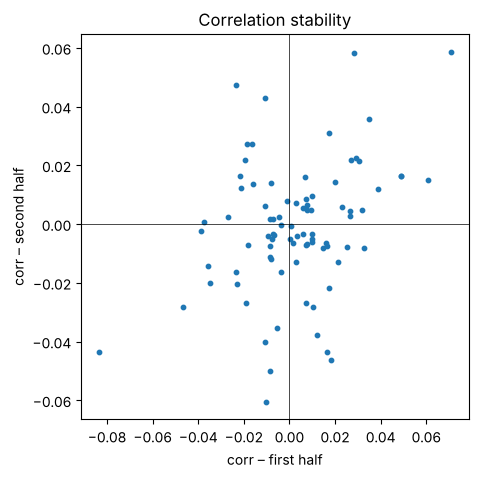

rank correlation between halves: 0.241


In [13]:
# Is the correlation stable over time? Compare the first and second half.
half = len(tr) // 2
c1 = tr.iloc[:half][feats].corrwith(tr.iloc[:half][D.TARGET])
c2 = tr.iloc[half:][feats].corrwith(tr.iloc[half:][D.TARGET])
plt.figure(figsize=(5, 5)); plt.scatter(c1, c2, s=10)
plt.axhline(0, c='k', lw=.5); plt.axvline(0, c='k', lw=.5)
plt.xlabel('corr – first half'); plt.ylabel('corr – second half'); plt.title('Correlation stability')
plt.show()
print('rank correlation between halves:', round(c1.corr(c2, method='spearman'), 3))

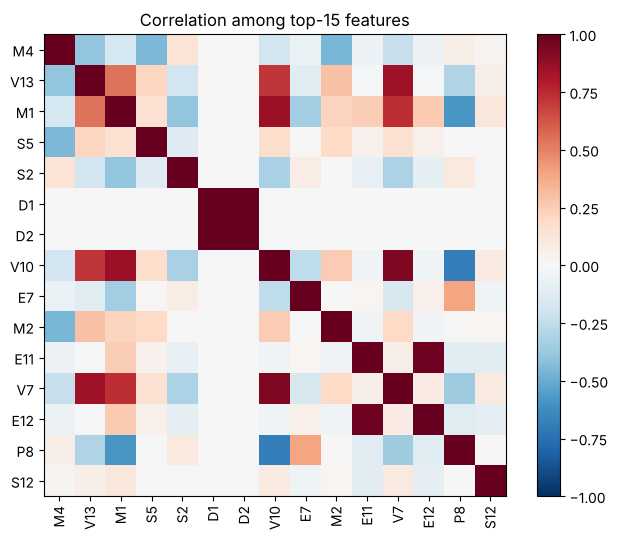

In [14]:
top = corr.abs().sort_values(ascending=False).index[:15]
plt.figure(figsize=(8, 6))
plt.imshow(tr[top].corr(), cmap='RdBu_r', vmin=-1, vmax=1)
plt.xticks(range(len(top)), top, rotation=90); plt.yticks(range(len(top)), top)
plt.colorbar(); plt.title('Correlation among top-15 features'); plt.show()

### EDA takeaways
- **Data size:** 9,048 trading days and 94 anonymised features in 7 groups (D, E, I, M, P, S, V). The S&P 500 returned about 11% per year over the training period.
- **Missing values:** Early history is mostly empty. D features are complete, but M (25% missing on average), S (20%) and V (20%) have the most gaps. Some features start very late (E7 is 77% missing and only appears at date_id 6969), and the first row with every feature present is date_id 6969. → We drop the oldest mostly-empty rows (before ~date_id 1006) and forward-fill the rest, never using future values.
- **Target distribution:** Daily excess returns average almost zero (std ≈ 1.06%). They are slightly left-skewed (skew −0.18), with fat tails (kurtosis 2.2), and 51.7% of days are positive. The extremes are symmetric at about ±4%, which suggests the target has been clipped.
- **Returns are hard to predict:** Autocorrelation of returns is close to zero at every lag (lag 1: −0.045).
- **Volatility is predictable:** Absolute returns are strongly autocorrelated (0.24 at lag 1, still 0.21 at lag 20). Rolling 1-year volatility ranges from 6.7% to 34%. → Lowering the position in high-volatility periods is a promising strategy idea.
- **Weak, unstable signal:** The largest feature–target correlations are only about 0.06 (M4 −0.067, V13 +0.062, M1 +0.046). The rank correlation of feature correlations between the two halves of the data is just 0.24. → Models need strong regularisation and time-based (walk-forward) validation; random K-fold would leak future information.
- **Metric insight:** Holding a constant position of 1 (buy and hold) scores 0.463 on the competition metric. A constant 0.8 scores slightly higher (0.471) and 1.2 scores lower (0.446). This is the baseline every model must beat.
- **Feature availability over time:** For roughly the first 1,000 days only the 9 D (dummy) features exist (≈10% of features). Availability then jumps to ~77% and slowly rises to 100% by date_id ~7000.
- **Clipping:** The return histogram shows small spikes at the ±4% edges, which supports the idea that the target was clipped.
- **Drawdowns and volatility:** The market grows over the long run but has two clear drawdowns (around date_id 2200–3300 and 4700–5000). The sharpest one coincides with the volatility peak (~34%), so large losses tend to come with high volatility. This supports reducing exposure when volatility is high.
- **Volatility regimes:** Volatility switches between calm periods (~10%) and stress periods (25–34%), with several spikes in recent years too.
- **Long memory in volatility:** Autocorrelation of |returns| peaks at lag 2 (~0.30) and decays very slowly up to lag 20, so recent volatility is a useful predictor of future volatility. Returns show slight negative autocorrelation at lag 1 (−0.045), a hint of short-term mean reversion.

## 6. Baselines

Every baseline outputs a **daily position in [0, 2]** and is scored with the competition metric
(`src/utils.py → adjusted_sharpe`). Models live in `src/models.py`:

| Baseline | Idea |
|----------|------|
| `constant_1` | Buy & hold: position = 1 every day. **The benchmark to beat.** |
| `best_constant` | The constant position that scored best on the training period. |
| `vol_target_21d`, `vol_target_63d` | Volatility targeting: position = long-run vol / recent vol (1 or 3 months), capped at 1.5. Motivated by volatility clustering in the EDA. |
| `momentum_252d` | Trend rule: position 1.2 if the past year was positive, else 0.6. |
| `ridge`, `elasticnet` | Regularised linear regression on all 94 features predicting next-day excess return; the standardised prediction is mapped to `1 + 0.5 × signal`. |
| `lightgbm` | Gradient-boosted trees (small, regularised) on all features – a non-linear version of the same idea, same signal → position mapping. |

**Validation – walk-forward (expanding window).** Financial data is ordered in time, so random K-fold would
let the model learn from the future. Instead we train on everything up to a date and score the next
block of ~1,340 days, five times:

```
fold 0: [train..........][valid]
fold 1: [train..................][valid]
...
fold 4: [train..........................................][valid]
```

In [15]:
from src import models as M

df = D.add_lagged_returns(D.drop_early_rows(train))
folds = list(D.walk_forward_folds(len(df), n_folds=5))
pd.DataFrame([{'fold': k, 'train_days': len(t), 'valid_days': len(v),
               'valid_from': df.date_id.iloc[v[0]], 'valid_to': df.date_id.iloc[v[-1]]}
              for k, (t, v) in enumerate(folds)]).set_index('fold')

,train_days,valid_days,valid_from,valid_to
fold,,,,
0,1342,1340,2348,3687
1,2682,1340,3688,5027
2,4022,1340,5028,6367
3,5362,1340,6368,7707
4,6702,1340,7708,9047


In [16]:
models = M.baseline_zoo()
table, per_fold = U.compare_models(models, df, folds)
table.round(3)

,mean_score,std_score,folds_beating_market,mean_position,ann_vol
model,,,,,
vol_target_21d,0.452,0.568,4,1.156,0.166
momentum_252d,0.436,0.449,3,1.056,0.171
vol_target_63d,0.420,0.490,2,1.147,0.170
constant_1,0.418,0.514,0,1.000,0.175
elasticnet,0.390,0.499,2,1.258,0.285
lightgbm,0.385,0.411,1,1.047,0.244
ridge,0.327,0.425,1,1.312,0.292
best_constant,0.315,0.407,1,0.640,0.114


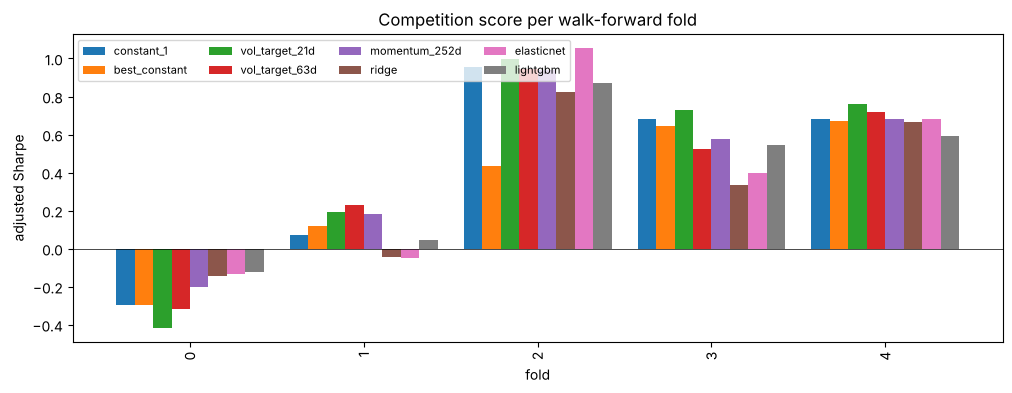

In [17]:
scores = pd.DataFrame({name: res['score'] for name, res in per_fold.items()})
ax = scores.plot.bar(figsize=(12, 4), width=0.85)
ax.axhline(0, color='k', lw=.5)
ax.set(title='Competition score per walk-forward fold', xlabel='fold', ylabel='adjusted Sharpe')
ax.legend(ncol=4, fontsize=8, loc='upper left')
plt.show()

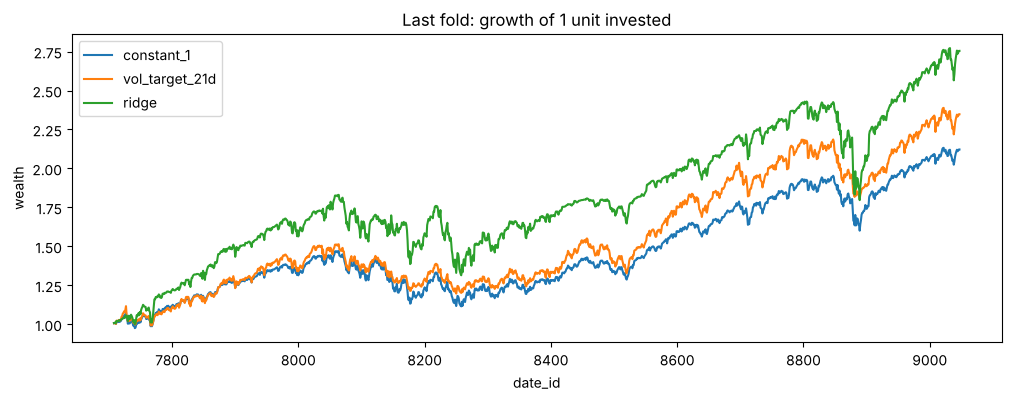

In [18]:
# Wealth curves on the most recent fold
tr_idx, va_idx = folds[-1]
fig, ax = plt.subplots(figsize=(12, 4))
valid = df.iloc[va_idx]
for name in ['constant_1', 'vol_target_21d', 'ridge']:
    m = models[name].fit(df.iloc[tr_idx])
    bt = U.backtest(valid, m.predict_position(valid))
    ax.plot(bt['date_id'], bt['strategy_wealth'], label=name)
ax.set(title='Last fold: growth of 1 unit invested', xlabel='date_id', ylabel='wealth'); ax.legend()
plt.show()

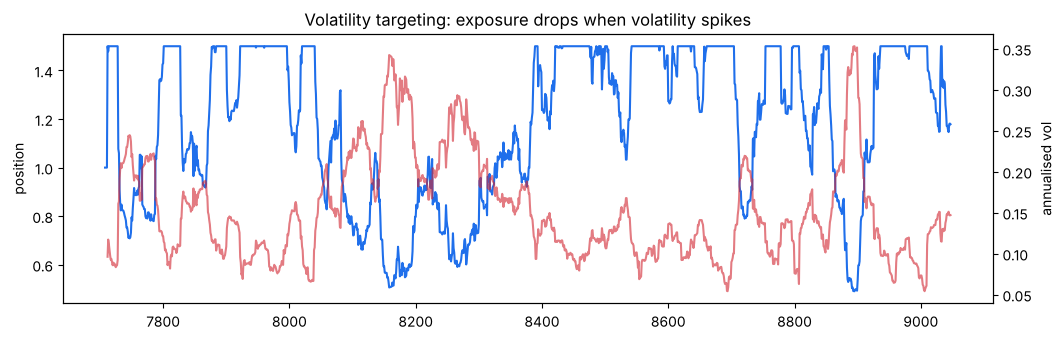

In [19]:
# Position chosen by volatility targeting over the last fold
vt = models['vol_target_21d'].fit(df.iloc[tr_idx])
fig, ax1 = plt.subplots(figsize=(12, 3.5))
ax1.plot(valid['date_id'], vt.predict_position(valid), color='#1f6feb', label='position')
ax1.set_ylabel('position')
ax2 = ax1.twinx()
ax2.plot(valid['date_id'], M.realised_vol(valid['lagged_forward_returns'], 21) * np.sqrt(252),
         color='#d1242f', alpha=.6, label='21-day vol')
ax2.set_ylabel('annualised vol')
ax1.set_title('Volatility targeting: exposure drops when volatility spikes')
plt.show()

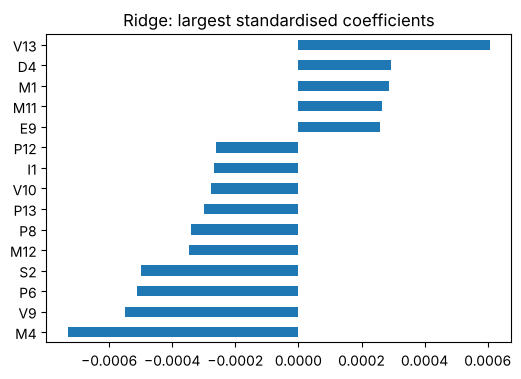

In [20]:
# Which features does Ridge rely on? (fitted on all but the last fold)
ridge = models['ridge'].fit(df.iloc[tr_idx])
coef = ridge.coefficients().head(15)
coef.sort_values().plot.barh(figsize=(6, 4), title='Ridge: largest standardised coefficients')
plt.show()

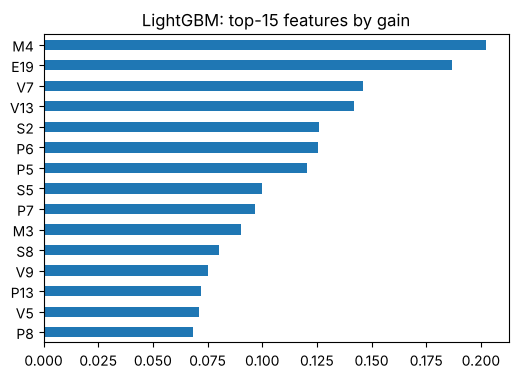

Features in both top-15 lists (Ridge and LightGBM): ['M4', 'P13', 'P6', 'P8', 'S2', 'V13', 'V9']


In [21]:
# LightGBM: which features carry the most split gain? (fitted on all but the last fold)
lgbm = models['lightgbm'].fit(df.iloc[tr_idx])
imp = lgbm.feature_importance().head(15)
imp.sort_values().plot.barh(figsize=(6, 4), title='LightGBM: top-15 features by gain')
plt.show()
print('Features in both top-15 lists (Ridge and LightGBM):', sorted(set(imp.index) & set(coef.index)))

### Baseline takeaways
*(See the summary table above; numbers are the mean adjusted Sharpe over the 5 walk-forward folds.)*
- **Buy & hold is hard to beat.** Only the simple rule-based strategies come close to or beat it.
- **Volatility targeting is the best baseline** (≈0.45 vs ≈0.42 for buy & hold) and beats the market in 4 of 5 folds.
  It lowers exposure when recent volatility is high, which confirms the EDA finding about volatility clustering.
- **Linear models on the raw features do worse than buy & hold.** Their positions swing a lot, so the strategy
  becomes much more volatile than the market (~29% vs ~17% annual vol) and is penalised by the metric.
  The feature signal is weak and unstable, as the EDA suggested.
- **Making more money ≠ scoring higher.** In the last fold Ridge ends with the highest wealth (≈2.75× vs ≈2.1× for
  buy & hold) but scores *lower* than buy & hold, because its swings make it far more volatile. The metric rewards
  return per unit of risk, not raw return.
- **A non-linear model does not fix this.** LightGBM scores ≈0.39 and beats buy & hold in only 1 of 5 folds.
  With such a weak signal, extra model flexibility mostly fits noise.
- **The best constant from the past does not carry over** – the optimal level changes over time.
- **Fold scores vary a lot** (from negative in the earliest fold to ~1.0), so a single train/test split
  would be misleading; walk-forward validation is necessary.

**Conclusion:** the simplest idea from the EDA – scale exposure by recent volatility – is the strongest baseline.
Predicting the *size of the risk* works better than predicting the *direction of the return*.

## 7. Kaggle submission

The best baseline in walk-forward validation, **volatility targeting (21 days)**, was prepared for submission in
`kaggle_submission.ipynb`. The notebook loads the same `src/` code, fits the model on the full training data and answers
the competition's evaluation API one day at a time (`src/models.py → OnlinePredictor`).

**Status:** the competition closed on 2026-06-26 and Kaggle has disabled late submissions
("Submissions have been disabled for this competition", checked on 2026-11-10), so no public score could be obtained.
Instead, the submission notebook was verified with the official `kaggle_evaluation` gateway in a local dry run:
it runs end to end, and its day-by-day predictions are identical to the predictions computed on the whole history at once.
The walk-forward score above (≈0.45 over ~6,700 days) is our estimate of the model's performance.

## Summary of Assignment 1
- **EDA:** weak and unstable return signal, many missing values in early history, strong volatility clustering.
- **Baselines:** volatility targeting is the only approach that beats buy & hold consistently (4/5 folds);
  linear models and LightGBM on raw features do not.
- **Assignment 2 direction:** combine a carefully regularised return signal with volatility-based position sizing,
  add features built from lagged returns (realised volatility, momentum), and tune the position mapping with
  walk-forward validation.